# LightGBM Model

Question B's main forecasting model. Trains LightGBM on four nested feature sets
(M1–M4) to test whether indoor conditions and outdoor weather improve a
day-ahead forecast of zone AC load. Reads the Stage 1 screened dataset from
[`../Feature Selection/Output/`](../Feature%20Selection/Output/).

## Setup

Install LightGBM and import the libraries used throughout.

In [1]:
%pip install lightgbm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")   # silence a harmless joblib warning on Windows

import time
import warnings
from itertools import product
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings("ignore", message=".*eval_set.*")   # LightGBM deprecation notice

## Configurations

Paths, target column, feature sets, baseline names, the LightGBM parameter grid,
and the final model choice.

The model data and the feature dictionary come from
[`../Feature Selection/Output/`](../Feature%20Selection/Output/), the Stage 1
screened versions. Stage 1 has already excluded `month`, `floor` and
`is_weekend`, dropped the leakage flags, and masked the F5_Z1 indoor readings
(its sensor measures AC supply air, not room air). The baseline predictions are
unaffected by screening, so they still come from `../cleaned_data/`.

In [3]:
DATA_DIR = Path("../cleaned_data")                  # baseline predictions (not affected by screening)
SCREENED_DIR = Path("../Feature Selection/Output")  # Stage 1 screened model data + dictionary
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "ac_load_kw"
CATEGORICAL = ["zone_code"]          # let LightGBM treat the zone as a category
SETS = ["M1", "M2", "M3", "M4"]
LABELS = {"M1": "M1: calendar + AC lags",
          "M2": "M2: calendar + AC lags + indoor",
          "M3": "M3: calendar + AC lags + weather",
          "M4": "M4: calendar + AC lags + indoor + weather"}
BASELINES = ["B1 seasonal naive", "B2 average profile", "B3 calendar + AC lags"]
SEED = 42

# Same search for every set. l1 objective aligns with MAE/WAPE; l2 with RMSE.
PARAM_GRID = {
    "objective": ["regression", "regression_l1"],
    "num_leaves": [31, 63],
    "min_child_samples": [100],
}

# n_estimators is high so early stopping, not the cap, decides the tree count
BASE_PARAMS = dict(learning_rate=0.05, feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1,
                   lambda_l2=1.0, n_estimators=10_000, random_state=SEED, verbose=-1)

PERM_REPEATS = 3            # shuffles per feature for permutation importance
SHAP_SAMPLE = 2000          # rows used for SHAP (mean |SHAP| is stable on a sample)
FINAL_SET = "M1"            # exported model (see "Export final model as wrapper")

### Logging helpers

Console output for the long-running steps.

In [4]:
def log(msg=""):
    print(msg, flush=True)


def banner(title):
    log("\n" + "=" * 78)
    log(title)
    log("=" * 78)

## Import data

Load the Stage 1 screened model dataset and feature dictionary, plus the
baseline predictions. Read the M1–M4 feature lists from the dictionary, tag each
feature with its group (indoor, weather, AC lag, calendar/zone), and split into
train / validation / test.

In [5]:
t0 = time.time()
df = pd.read_parquet(SCREENED_DIR / "question_b_model_data_screened.parquet")
fdict = pd.read_csv(SCREENED_DIR / "question_b_feature_dictionary_screened.csv")
baselines = pd.read_parquet(DATA_DIR / "question_b_baseline_predictions.parquet")

FEATURES = {m: fdict.loc[fdict[m].eq("Yes"), "column"].tolist() for m in SETS}
GROUP = {c: ("indoor" if c.startswith("indoor") else
             "weather" if c.startswith(("outdoor", "rainfall", "solar")) else
             "AC lag" if c.startswith("ac_load") else "calendar/zone") for c in FEATURES["M4"]}

df["zone_code"] = df["zone_code"].astype("category")
train = df[df.split == "train"]
valid = df[df.split == "validation"]
full = df[df.split.isin(["train", "validation"])]
test = df[df.split == "test"]
OP_VALID = valid.is_operating_hours.eq(1).values
log(f"Loaded {len(df):,} rows in {time.time() - t0:.1f}s | train {len(train):,} | "
    f"validation {len(valid):,} | test {len(test):,}")
for m in SETS:
    log(f"  {LABELS[m]:<42} {len(FEATURES[m]):>2} features")

df.head(10)

Loaded 209,119 rows in 1.2s | train 111,779 | validation 46,773 | test 50,567


  M1: calendar + AC lags                      7 features


  M2: calendar + AC lags + indoor            13 features


  M3: calendar + AC lags + weather           15 features


  M4: calendar + AC lags + indoor + weather  21 features


,zone_id,timestamp,split,is_operating_hours,day_type,ac_load_kw,zone_code,hour,weekday,is_holiday,...,indoor_humidity_pct_last_week,indoor_humidity_pct_yesterday_avg,outdoor_temp_hourly_c,outdoor_temp_daily_avg_c,outdoor_humidity_hourly_pct,outdoor_humidity_daily_avg_pct,rainfall_hourly_mm,rainfall_daily_total_mm,solar_radiation_hourly_wm2,solar_radiation_daily_total_mjm2
0,F2_Z1,2018-07-01 00:00:00,test,0,weekend,0.0,0,0,6,0,...,NaN,NaN,27.1,28.8,88,74,0.0,0.1,0.0,22.76
1,F2_Z1,2018-07-01 01:00:00,test,0,weekend,0.0,0,1,6,0,...,NaN,NaN,26.8,28.8,88,74,0.0,0.1,0.0,22.76
2,F2_Z1,2018-07-01 02:00:00,test,0,weekend,0.0,0,2,6,0,...,NaN,NaN,26.5,28.8,86,74,0.0,0.1,0.0,22.76
3,F2_Z1,2018-07-01 03:00:00,test,0,weekend,0.0,0,3,6,0,...,NaN,NaN,25.9,28.8,84,74,0.0,0.1,0.0,22.76
4,F2_Z1,2018-07-01 04:00:00,test,0,weekend,0.0,0,4,6,0,...,NaN,NaN,25.5,28.8,84,74,0.0,0.1,0.0,22.76
5,F2_Z1,2018-07-01 05:00:00,test,0,weekend,0.0,0,5,6,0,...,NaN,NaN,25.4,28.8,85,74,0.0,0.1,0.0,22.76
6,F2_Z1,2018-07-01 06:00:00,test,0,weekend,0.0,0,6,6,0,...,NaN,NaN,25.1,28.8,86,74,0.0,0.1,70.0,22.76
7,F2_Z1,2018-07-01 07:00:00,test,0,weekend,0.0,0,7,6,0,...,NaN,NaN,26.1,28.8,82,74,0.0,0.1,261.0,22.76
8,F2_Z1,2018-07-01 08:00:00,test,0,weekend,0.0,0,8,6,0,...,NaN,NaN,27.8,28.8,74,74,0.0,0.1,462.0,22.76
9,F2_Z1,2018-07-01 09:00:00,test,0,weekend,0.0,0,9,6,0,...,NaN,NaN,29.3,28.8,67,74,0.0,0.1,626.0,22.76


## Helper functions

Metrics (MAE, RMSE, CV(RMSE), NMBE, WAPE), model fitting with early stopping,
and the grid-search tuner.

In [6]:
def metrics(y, yhat):
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)
    err = y - yhat
    ybar = y.mean()
    rmse = np.sqrt(np.mean(err ** 2))
    return {"n": len(y), "MAE": np.mean(np.abs(err)), "RMSE": rmse,
            "CV(RMSE)%": 100 * rmse / ybar,
            "NMBE%": 100 * err.sum() / (len(y) * ybar),       # +ve = under-predicts
            "WAPE%": 100 * np.abs(err).sum() / np.abs(y).sum()}


def wape(y, yhat):
    return 100 * np.abs(np.asarray(y) - yhat).sum() / np.abs(np.asarray(y)).sum()


def progress_callback(every, label):
    start = time.time()

    def _cb(env):
        i, n = env.iteration + 1, env.end_iteration
        if i % every == 0 or i == n:
            el = time.time() - start
            log(f"    [{label}] tree {i:>5}/{n} ({100 * i / n:5.1f}%) | "
                f"elapsed {el:6.1f}s | ETA {el / i * (n - i):6.1f}s")
    _cb.order = 30
    return _cb


def fit(params, X, y, X_val=None, y_val=None, n_estimators=None, callbacks=None):
    p = {**BASE_PARAMS, **params}
    if n_estimators:
        p["n_estimators"] = n_estimators
    model = lgb.LGBMRegressor(**p)
    kw = {"categorical_feature": [c for c in CATEGORICAL if c in X.columns],
          "callbacks": list(callbacks or [])}
    if X_val is not None:
        kw.update(eval_set=[(X_val, y_val)], eval_metric="l1")
        kw["callbacks"].append(lgb.early_stopping(200, verbose=False))
    model.fit(X, y, **kw)
    return model


def predict(model, X):
    return np.clip(model.predict(X), 0, None)


def tune(features, label):
    # Grid search on train -> validation; returns all results, the best row and the best model.
    rows, models = [], []
    combos = list(product(*PARAM_GRID.values()))
    for i, values in enumerate(combos, 1):
        params = dict(zip(PARAM_GRID, values))
        t = time.time()
        model = fit(params, train[features], train[TARGET], valid[features], valid[TARGET])
        pred = predict(model, valid[features])
        r = {**params, "best_iter": model.best_iteration_,
             "val_WAPE_all%": wape(valid[TARGET], pred),
             "val_WAPE_op%": wape(valid[TARGET][OP_VALID], pred[OP_VALID])}
        rows.append(r)
        models.append(model)
        log(f"  [{label} {i}/{len(combos)}] {params} iter={r['best_iter']:>4} | "
            f"val WAPE all {r['val_WAPE_all%']:.2f}% op {r['val_WAPE_op%']:.2f}% | {time.time() - t:.0f}s")
    res = pd.DataFrame(rows)
    best_i = int(res["val_WAPE_op%"].idxmin())
    best = res.loc[best_i].to_dict()
    log(f"  -> best {label}: {as_params(best)} iter={int(best['best_iter'])} "
        f"val WAPE op {best['val_WAPE_op%']:.2f}%")
    return res.sort_values("val_WAPE_op%"), best, models[best_i]


def as_params(best):
    return {"objective": best["objective"], "num_leaves": int(best["num_leaves"]),
            "min_child_samples": int(best["min_child_samples"])}

## 1. M1–M4 models

The research question is whether **indoor conditions** and **outdoor weather**
improve the forecast. Four nested feature sets answer it: every set uses the same
method, the same data and the same settings search, and only the inputs change.

| Set | Features | Answers |
|---|---|---|
| **M1** | calendar + AC lags | How far do time patterns and the zone's own AC history get us? |
| **M2** | M1 + indoor temperature / humidity lags | Do indoor conditions add anything? |
| **M3** | M1 + outdoor weather | Does the weather (forecast) add anything? |
| **M4** | M1 + indoor + weather | Do they add anything together? |

**Fairness rules**
- All four sets use the Stage 1 screened data and the M1–M4 lists from the screened dictionary.
- Each set gets the **same grid search** (L2 or L1 objective × 31 or 63 leaves) on train → validation and keeps its best settings.
- The tree limit is 10,000, so early stopping (not the cap) decides how many trees each model gets.
- Validation WAPE on operating hours compares the sets; the test period (Jul–Sep 2018) is scored once, in the Test section.

In [7]:
banner("STEP 1/2  Tune M1-M4 on train -> validation (same grid for every set)")
tuning, best, val_models = {}, {}, {}
for m in SETS:
    log(f"\n{LABELS[m]} ({len(FEATURES[m])} features)")
    tuning[m], best[m], val_models[m] = tune(FEATURES[m], m)

val_table = pd.DataFrame([{**as_params(best[m]), "trees": int(best[m]["best_iter"]),
                           "val WAPE op %": best[m]["val_WAPE_op%"],
                           "val WAPE all %": best[m]["val_WAPE_all%"]} for m in SETS],
                         index=[LABELS[m] for m in SETS])
val_table["vs M1 op (pp)"] = val_table["val WAPE op %"] - val_table.loc[LABELS["M1"], "val WAPE op %"]
display(val_table.round(2))

STEP 1/2  Tune M1-M4 on train -> validation (same grid for every set)



M1: calendar + AC lags (7 features)


  [M1 1/4] {'objective': 'regression', 'num_leaves': 31, 'min_child_samples': 100} iter= 215 | val WAPE all 20.41% op 12.16% | 1s


  [M1 2/4] {'objective': 'regression', 'num_leaves': 63, 'min_child_samples': 100} iter= 140 | val WAPE all 20.76% op 12.16% | 1s


  [M1 3/4] {'objective': 'regression_l1', 'num_leaves': 31, 'min_child_samples': 100} iter=1347 | val WAPE all 17.16% op 12.02% | 5s


  [M1 4/4] {'objective': 'regression_l1', 'num_leaves': 63, 'min_child_samples': 100} iter=5918 | val WAPE all 17.31% op 11.80% | 30s


... (16 outputs left out)

  [M4 3/4] {'objective': 'regression_l1', 'num_leaves': 31, 'min_child_samples': 100} iter=8959 | val WAPE all 19.65% op 12.71% | 48s


  [M4 4/4] {'objective': 'regression_l1', 'num_leaves': 63, 'min_child_samples': 100} iter=3719 | val WAPE all 20.20% op 12.83% | 26s


  -> best M4: {'objective': 'regression_l1', 'num_leaves': 31, 'min_child_samples': 100} iter=8959 val WAPE op 12.71%


,objective,num_leaves,min_child_samples,trees,val WAPE op %,val WAPE all %,vs M1 op (pp)
M1: calendar + AC lags,regression_l1,63,100,5918,11.80,17.31,0.00
M2: calendar + AC lags + indoor,regression_l1,63,100,5662,11.22,16.75,-0.58
M3: calendar + AC lags + weather,regression_l1,31,100,5430,12.69,18.89,0.89
M4: calendar + AC lags + indoor + weather,regression_l1,31,100,8959,12.71,19.65,0.91


## 2. Feature importance in M1–M4

What each feature contributes inside each set's tuned model, measured on the
**validation** data:
- **Permutation importance:** how much operating-hours WAPE rises when the feature's values are replaced with values drawn at random from all validation hours. Drawing from all hours (not just operating hours) is what lets calendar features such as `is_holiday` and `weekday` show their effect, since operating hours are always non-holiday weekdays.
- **Mean |SHAP|:** how many kW, on average, the feature moves a prediction.

This explains what each model relies on. It is not used to drop features.

In [8]:
banner("STEP 2/2  Feature importance on VALIDATION (permutation + SHAP)")
rng = np.random.default_rng(SEED)
valid_op = valid[OP_VALID]
importance = []
for m in SETS:
    t = time.time()
    model, feats = val_models[m], FEATURES[m]
    X = valid_op[feats].copy()
    base = wape(valid_op[TARGET], predict(model, X))
    shap = model.predict(valid[feats].sample(n=SHAP_SAMPLE, random_state=SEED), pred_contrib=True)[:, :-1]
    for j, c in enumerate(feats):
        original = X[c].copy()
        scores = []
        for _ in range(PERM_REPEATS):
            X[c] = valid[c].values[rng.permutation(len(valid))[:len(X)]]   # values from all validation hours
            if c in CATEGORICAL:
                X[c] = X[c].astype(original.dtype)
            scores.append(wape(valid_op[TARGET], predict(model, X)) - base)
        X[c] = original
        importance.append({"set": m, "feature": c, "group": GROUP[c],
                           "perm_WAPE_increase_pp": np.mean(scores), "perm_sd_pp": np.std(scores),
                           "mean_abs_shap_kW": np.abs(shap[:, j]).mean()})
    log(f"  {m}: {len(feats)} features done in {time.time() - t:.0f}s")

importance = pd.DataFrame(importance)
importance.to_csv(OUT_DIR / "feature_comparison.csv", index=False)

STEP 2/2  Feature importance on VALIDATION (permutation + SHAP)


  M1: 7 features done in 143s


  M2: 13 features done in 237s


  M3: 15 features done in 107s


  M4: 21 features done in 208s


### Present the feature importance

Table of permutation importance (WAPE increase when shuffled, pp) for every
feature in every set, and one chart per set coloured by feature group.

In [9]:
%matplotlib inline

set,Group,M1,M2,M3,M4
feature,,,,,
ac_load_kw_last_week,AC lag,15.98,16.62,19.04,19.79
weekday,calendar/zone,23.29,22.23,17.46,16.87
ac_load_kw_yesterday,AC lag,14.30,16.55,12.70,15.37
is_holiday,calendar/zone,7.44,7.02,6.73,6.68
solar_radiation_hourly_wm2,weather,NaN,NaN,7.86,6.63
hour,calendar/zone,12.41,10.63,6.58,5.89
zone_code,calendar/zone,6.33,6.20,5.13,5.01
indoor_temp_c_last_week,indoor,NaN,1.43,NaN,1.27
outdoor_temp_daily_avg_c,weather,NaN,NaN,1.61,1.14


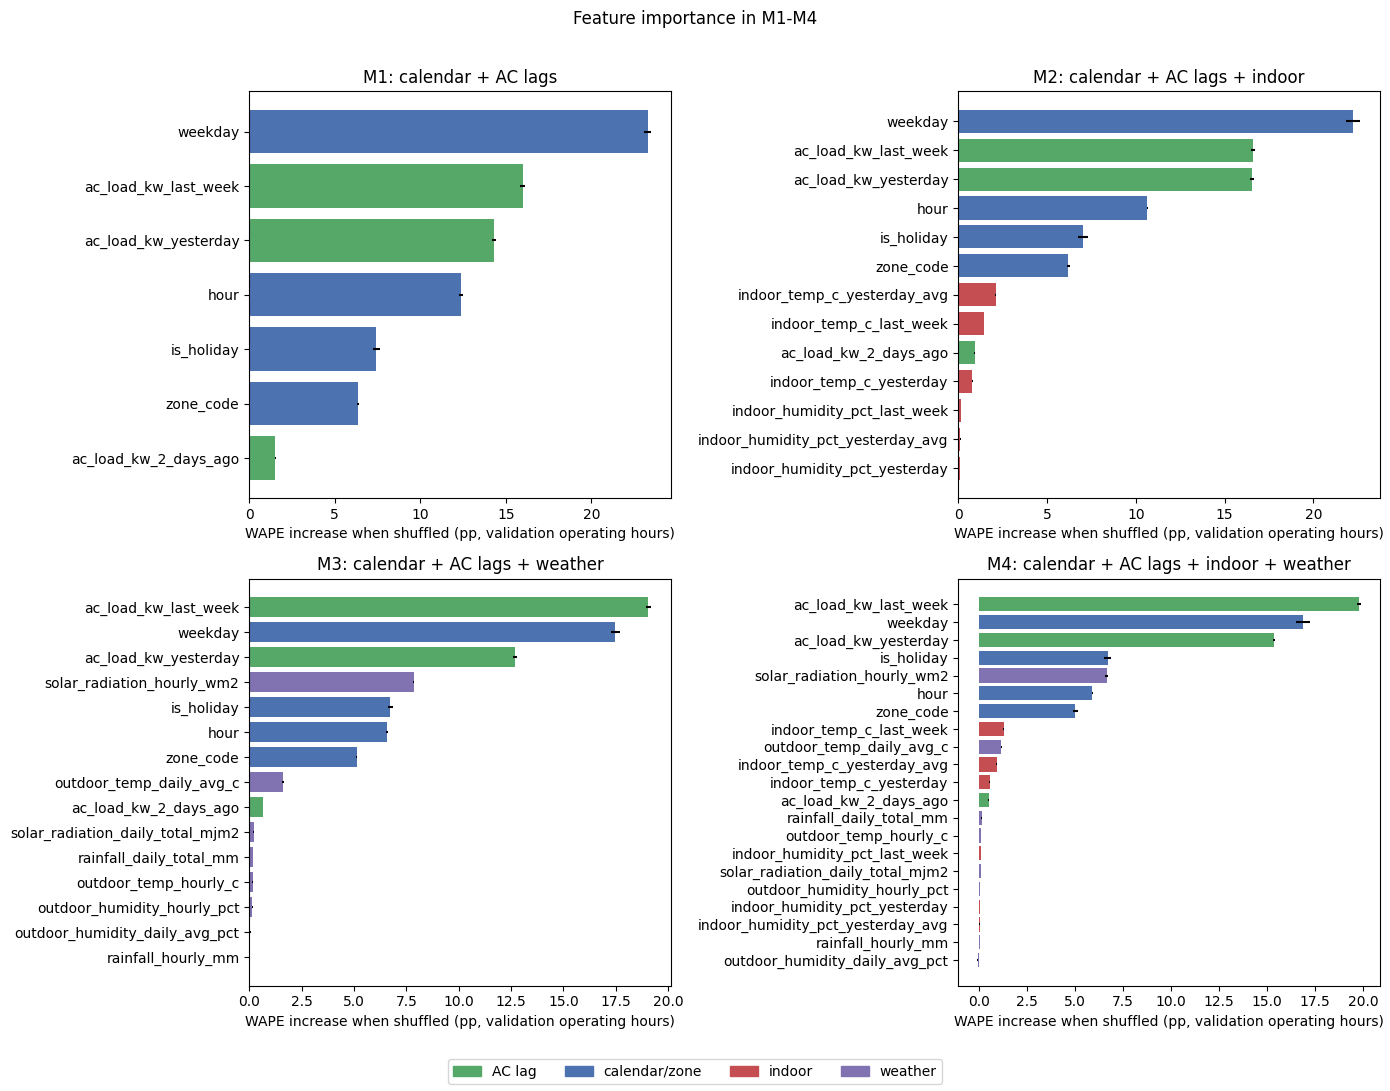

In [10]:
table = (importance.pivot(index="feature", columns="set", values="perm_WAPE_increase_pp")
         .reindex(FEATURES["M4"]).round(2))
table.insert(0, "Group", pd.Series(GROUP))
display(table.sort_values("M4", ascending=False))

colors = {"AC lag": "#55A868", "calendar/zone": "#4C72B0", "indoor": "#C44E52", "weather": "#8172B2"}
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, m in zip(axes.flat, SETS):
    t = importance[importance.set == m].sort_values("perm_WAPE_increase_pp")
    ax.barh(t.feature, t.perm_WAPE_increase_pp, xerr=t.perm_sd_pp, color=t.group.map(colors))
    ax.set(title=LABELS[m], xlabel="WAPE increase when shuffled (pp, validation operating hours)")
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()], colors,
           loc="lower center", ncol=4)
fig.suptitle("Feature importance in M1-M4")
fig.tight_layout(rect=(0, 0.04, 1, 0.97))
fig.savefig(OUT_DIR / "feature_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## Test

Retrain every set on train + validation (all of 2019) with its tuned settings,
then score the held-out 2018 test window against the baselines: headline
metrics, rain vs dry, and Diebold–Mariano tests for significance.

In [11]:
banner("Retrain M1-M4 on all 2019, predict test Jul-Sep 2018")
test_pred = test[["zone_id", "timestamp", "rainfall_hourly_mm"]].copy()
final_models = {}
for m in SETS:
    n_iter = int(best[m]["best_iter"] * len(full) / len(train))   # more data -> proportionally more trees
    log(f"  {LABELS[m]}: {len(FEATURES[m])} features, {n_iter} trees, {as_params(best[m])}")
    t = time.time()
    final_models[m] = fit(as_params(best[m]), full[FEATURES[m]], full[TARGET], n_estimators=n_iter,
                          callbacks=[progress_callback(max(50, n_iter // 5), m)])
    test_pred[m] = predict(final_models[m], test[FEATURES[m]])
    log(f"  -> trained + predicted in {time.time() - t:.1f}s")

final_models[FINAL_SET].booster_.save_model(str(OUT_DIR / "lgbm_final.txt"))
pd.DataFrame({"feature": FEATURES[FINAL_SET], "group": [GROUP[c] for c in FEATURES[FINAL_SET]]}
             ).to_csv(OUT_DIR / "final_features.csv", index=False)

Retrain M1-M4 on all 2019, predict test Jul-Sep 2018


  M1: calendar + AC lags: 7 features, 8394 trees, {'objective': 'regression_l1', 'num_leaves': 63, 'min_child_samples': 100}


    [M1] tree  1678/8394 ( 20.0%) | elapsed    6.2s | ETA   24.7s


    [M1] tree  3356/8394 ( 40.0%) | elapsed   12.7s | ETA   19.0s


    [M1] tree  5034/8394 ( 60.0%) | elapsed   19.2s | ETA   12.8s


    [M1] tree  6712/8394 ( 80.0%) | elapsed   25.6s | ETA    6.4s


... (23 outputs left out)

    [M4] tree 10164/12707 ( 80.0%) | elapsed   50.5s | ETA   12.6s


    [M4] tree 12705/12707 (100.0%) | elapsed   62.9s | ETA    0.0s


    [M4] tree 12707/12707 (100.0%) | elapsed   62.9s | ETA    0.0s


  -> trained + predicted in 82.9s


In [12]:
cmp = (baselines[baselines.period == "test"]
       .merge(test_pred, on=["zone_id", "timestamp"], how="left"))
cmp = cmp[cmp.scored == 1].copy()
assert cmp[BASELINES + SETS].notna().all().all(), "missing predictions on scored rows"
cmp.to_parquet(OUT_DIR / "test_predictions.parquet", index=False)

In [13]:
rows = []
for hours, mask in [("all hours", np.ones(len(cmp), bool)),
                    ("operating hours", cmp.is_operating_hours.eq(1).values)]:
    for c in BASELINES + SETS:
        rows.append({"hours": hours, "model": LABELS.get(c, c), **metrics(cmp.loc[mask, TARGET], cmp.loc[mask, c])})
results = pd.DataFrame(rows)
results.to_csv(OUT_DIR / "test_metrics.csv", index=False)

In [14]:
op = cmp[cmp.is_operating_hours.eq(1)]
rain = pd.DataFrame([{"condition": n, "model": LABELS.get(c, c), "WAPE%": wape(s[TARGET], s[c])}
                     for n, s in [("dry", op[op.rainfall_hourly_mm.eq(0)]),
                                  ("rain", op[op.rainfall_hourly_mm.gt(0)])]
                     for c in BASELINES + SETS]).pivot(index="model", columns="condition", values="WAPE%")
rain.to_csv(OUT_DIR / "test_rain_vs_dry.csv")

In [15]:
def diebold_mariano(frame, a, b, max_lag=24):
    # DM on absolute error, averaged across zones per hour; Newey-West variance.
    # DM < 0 => model a is more accurate than b.
    d = (np.abs(frame[TARGET] - frame[a]) - np.abs(frame[TARGET] - frame[b]))
    d = d.groupby(frame.timestamp).mean().sort_index().values
    n, dbar = len(d), d.mean()
    dc = d - dbar
    lrv = dc @ dc / n
    for k in range(1, max_lag + 1):
        lrv += 2 * (1 - k / (max_lag + 1)) * (dc[k:] @ dc[:-k]) / n
    dm = dbar / np.sqrt(lrv / n)
    return dm, 2 * stats.norm.sf(abs(dm))

In [16]:
dm_rows = []
for hours, frame in [("all hours", cmp), ("operating hours", op)]:
    for a, b in [("M2", "M1"), ("M3", "M1"), ("M4", "M1")] + [("M1", b) for b in BASELINES]:
        dm, p = diebold_mariano(frame, a, b)
        dm_rows.append({"hours": hours, "model": a, "vs": b, "DM": dm, "p_value": p,
                        "result": (f"{a} better" if dm < 0 else f"{a} worse") if p < 0.05 else "no significant difference"})
dm_tab = pd.DataFrame(dm_rows)
dm_tab.to_csv(OUT_DIR / "test_diebold_mariano.csv", index=False)

## Results (Using WAPE%)

Printed summary and WAPE bar charts for all hours and operating hours.

In [17]:
banner("RESULTS (test = Jul-Sep 2018, scored rows)")
log(results.to_string(index=False))
log("\nRain vs dry (operating hours, WAPE%):")
log(rain.to_string())
log("\nDiebold-Mariano (DM < 0 => first model more accurate):")
log(dm_tab.to_string(index=False))
log(f"\nDone in {(time.time() - t0) / 60:.1f} min. Outputs in {OUT_DIR.resolve()}")

RESULTS (test = Jul-Sep 2018, scored rows)


          hours                                     model     n      MAE     RMSE  CV(RMSE)%      NMBE%     WAPE%
      all hours                         B1 seasonal naive 46064 1.197930 4.151608  98.179932  -1.270936 28.329428
      all hours                        B2 average profile 46064 1.146502 3.002205  70.998098  -7.763172 27.113222
      all hours                     B3 calendar + AC lags 46064 1.673616 3.402832  80.472406 -12.111553 39.578769
      all hours                    M1: calendar + AC lags 46064 0.708962 2.735198  64.683743   1.429942 16.765997
      all hours           M2: calendar + AC lags + indoor 46064 0.825814 2.783766  65.832324  -3.238159 19.529390
      all hours          M3: calendar + AC lags + weather 46064 0.777041 2.721750  64.365723   5.856446 18.375979
      all hours M4: calendar + AC lags + indoor + weather 46064 0.825846 2.751305  65.064671   2.066162 19.530158
operating hours                         B1 seasonal naive 12602 2.313099 4.768478  34.87


Rain vs dry (operating hours, WAPE%):


condition                                        dry       rain
model                                                          
B1 seasonal naive                          15.483016  18.048679
B2 average profile                         20.798047  18.413039
B3 calendar + AC lags                      17.022389  18.994462
M1: calendar + AC lags                      9.412472  11.263194
M2: calendar + AC lags + indoor            11.365860  13.851273
M3: calendar + AC lags + weather           11.003651  12.080653
M4: calendar + AC lags + indoor + weather  11.904425  12.848101



Diebold-Mariano (DM < 0 => first model more accurate):


          hours model                    vs         DM      p_value    result
      all hours    M2                    M1   8.672411 4.230636e-18  M2 worse
      all hours    M3                    M1   4.092697 4.263839e-05  M3 worse
      all hours    M4                    M1   6.218213 5.028492e-10  M4 worse
      all hours    M1     B1 seasonal naive  -3.733867 1.885623e-04 M1 better
      all hours    M1    B2 average profile -10.204073 1.901272e-24 M1 better
      all hours    M1 B3 calendar + AC lags -14.056601 7.017687e-45 M1 better
operating hours    M2                    M1   7.640219 2.168532e-14  M2 worse
operating hours    M3                    M1   2.830673 4.645014e-03  M3 worse
operating hours    M4                    M1   4.340362 1.422480e-05  M4 worse
operating hours    M1     B1 seasonal naive  -2.520559 1.171685e-02 M1 better
operating hours    M1    B2 average profile  -9.098561 9.153693e-20 M1 better
operating hours    M1 B3 calendar + AC lags  -6.033275 1.606699e


Done in 19.2 min. Outputs in C:\Users\zheng\OneDrive\Documents\SMU (Y3S1)\IS4001 Smart Building Analytics\3. Final Project\Repo\Qn_B\3-LightGBM\outputs


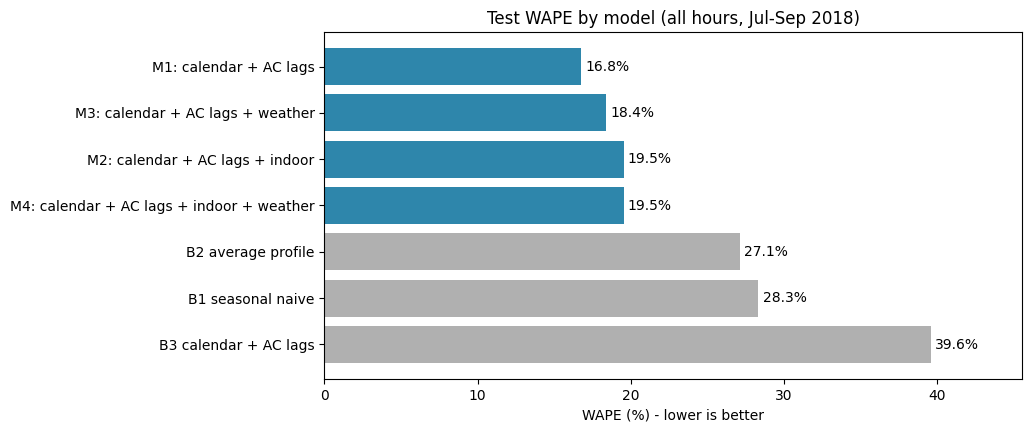

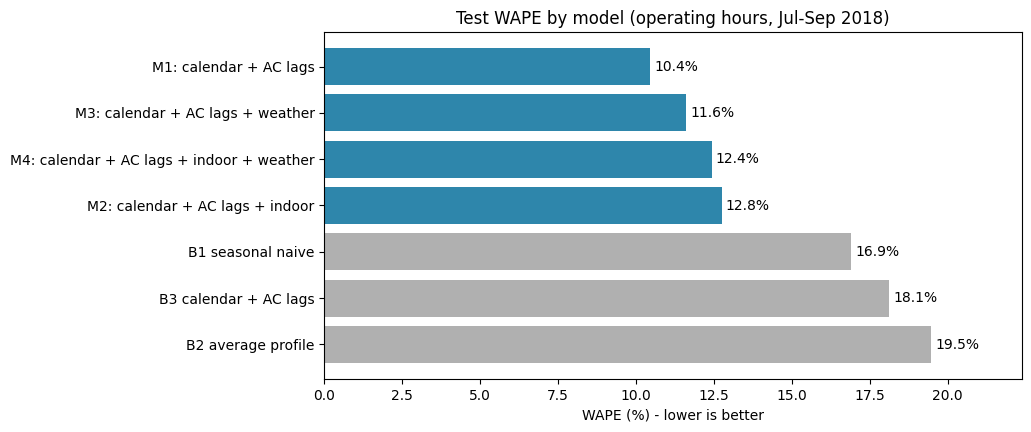

In [18]:
for hours in ["all hours", "operating hours"]:
    r = results[results.hours == hours].sort_values("WAPE%", ascending=False)
    colors = ["#2E86AB" if m.startswith("M") else "#B0B0B0" for m in r.model]
    fig, ax = plt.subplots(figsize=(9, 4.5))
    bars = ax.barh(r.model, r["WAPE%"], color=colors)
    ax.bar_label(bars, fmt="%.1f%%", padding=3)
    ax.set(xlabel="WAPE (%) - lower is better", title=f"Test WAPE by model ({hours}, Jul-Sep 2018)")
    ax.set_xlim(0, r["WAPE%"].max() * 1.15)
    fig.savefig(OUT_DIR / f"wape_{hours.replace(' ', '_')}.png", dpi=150, bbox_inches="tight")
    display(fig)
    plt.close(fig)